# DS483 Project - SMS Spam Detection

Dataset: SMS Spam Collection (UCI)

To run: Runtime -> Run all

# Week 1 - Task 1: Text Preprocessing

## Part 1 (Student 1): load the data, duplicates, class distribution, train/test split

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

### Load the data

The data file is in our GitHub repo. Each line has the label (ham or spam), a tab, then the message.

In [2]:
url = "https://raw.githubusercontent.com/zahrss0r/DS483-SMS-Spam-Detection-Project/main/data/SMSSpamCollection"

# sep="\t" because the file uses tab
# quoting=3 so the " inside some messages don't break the reading
df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"], quoting=3)

print("Number of messages:", len(df))
df.head()

Number of messages: 5574


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Missing values and duplicates

In [3]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [4]:
print("Duplicate messages:", df.duplicated(subset="message").sum())

Duplicate messages: 403


In [5]:
# duplicates in each class
duplicates = df[df.duplicated(subset="message")]
print(duplicates["label"].value_counts())

label
ham     309
spam     94
Name: count, dtype: int64


In [6]:
# messages that repeat the most
df["message"].value_counts().head(5)

,count
message,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not matured 8. Stylish 9. Simple Pls reply..,4
Okie,4


### Remove duplicates

If the same message is in the train data and the test data, the model already saw it, so the results will look better than they really are. So we keep only one copy of each message.

In [7]:
before = len(df)
df = df.drop_duplicates(subset="message")
after = len(df)

print("Before:", before)
print("After:", after)
print("Removed:", before - after)

Before: 5574
After: 5171
Removed: 403


### Class distribution

In [8]:
print(df["label"].value_counts())
print()
print(df["label"].value_counts(normalize=True) * 100)

label
ham     4518
spam     653
Name: count, dtype: int64

label
ham     87.371882
spam    12.628118
Name: proportion, dtype: float64


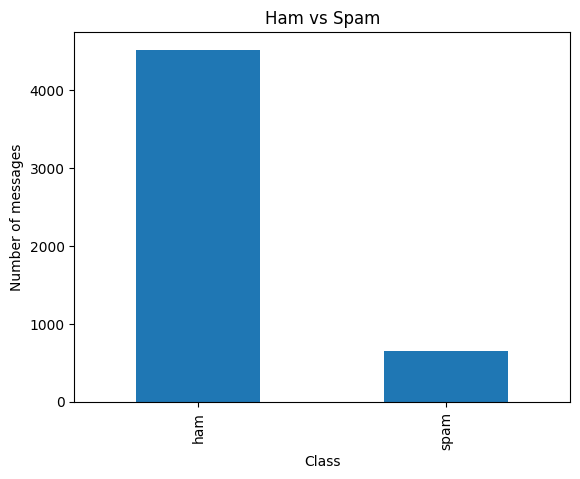

In [9]:
df["label"].value_counts().plot(kind="bar")
plt.title("Ham vs Spam")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.show()

Most messages are ham, so the data is not balanced. This is why accuracy alone is not enough, we will also look at precision, recall and F1.

### Change the label to numbers (ham = 0, spam = 1)

In [10]:
df["target"] = df["label"].map({"ham": 0, "spam": 1})
df.head()

,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


### Split the data (80% train, 20% test)

- random_state=42 so we get the same split every time we run
- stratify so train and test have the same percent of spam
- we will use this same split for all the models in the next tasks

In [11]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=42)

print("Train:", len(train_df))
print("Test:", len(test_df))

Train: 4136
Test: 1035


In [12]:
print("Train:")
print(train_df["label"].value_counts(normalize=True) * 100)
print()
print("Test:")
print(test_df["label"].value_counts(normalize=True) * 100)

Train:
label
ham     87.37911
spam    12.62089
Name: proportion, dtype: float64

Test:
label
ham     87.342995
spam    12.657005
Name: proportion, dtype: float64


### Examples

In [13]:
print("Ham:")
for m in df[df["label"] == "ham"]["message"].head(3):
    print("-", m)

print()
print("Spam:")
for m in df[df["label"] == "spam"]["message"].head(3):
    print("-", m)

Ham:
- Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
- Ok lar... Joking wif u oni...
- U dun say so early hor... U c already then say...

Spam:
- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
